In [1]:
def cut_regions_from_adata(adata, regions_per_sample):
    """
    Extract cells within specified rectangular regions based on each sample's own coordinate system.

    The input (x, y, width, height) is relative to each sample's coordinate system,
    with coordinate fields assumed to be 'array_col' (x) and 'array_row' (y).

    Parameters:
    ----------
    adata : AnnData
        Contains obs['batch'], obs['array_row'], obs['array_col'],
        and uns['spatial'] dictionary (keyed by sample name).

    regions_per_sample : list of tuples
        [(sample_id, x, y, width, height), ...]
        - x, y: starting coordinates in the sample's coordinate system
          (typically corresponding to array_col, array_row)
        - width, height: width and height of the cropping region

    Returns:
    -------
    dict: {sample_id: cropped_adata}
    """

    x, y, w, h = regions_per_sample
    # Step 1: Extract all cells from this sample
    tp = adata

    # Step 3: Retrieve coordinates (x = array_col, y = array_row)
    x_coords = tp.obsm['spatial'][:, 0]
    y_coords = tp.obsm['spatial'][:, 1]

    # Step 4: Define the cropping range (closed interval)
    x_min, x_max = x, x + w
    y_min, y_max = y, y + h

    # Step 5: Filter cells within the region
    in_region = (
        (x_coords >= x_min) & (x_coords <= x_max) &
        (y_coords >= y_min) & (y_coords <= y_max)
    )

    if not in_region.any():
        print(f"Warning: No cells in region ({x}, {y}, {w}, {h})")

    # Step 6: Crop and save
    tp_cropped = tp[in_region].copy()

    return tp_cropped

In [6]:
import squidpy as sq
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


def plot_HD(adata):
    # Treatment effect grouping
    treatment_effect = {
        "nS03": "good",
        "nS01": "poor",
        "nS02": "poor",
        "nS06": "good",
    }

    good_samples = [sample for sample, effect in treatment_effect.items() if effect == "good"]
    poor_samples = [sample for sample, effect in treatment_effect.items() if effect == "poor"]

    # Create a horizontal layout
    total_samples = len(good_samples) + len(poor_samples)
    fig, axes = plt.subplots(1, total_samples, figsize=(4 * total_samples, 6))

    gene1, gene2 =  "CCR7", "CCL19"
    celltypes_groupA =  ["T cell","B cell","Myeloid cell"]
    celltype_groupB = ["Stromal cell"]

    # Plot all samples
    for i, sample in enumerate(good_samples + poor_samples):
        tp = adata[adata.obs["batch"].isin([sample])].copy()
        tp.uns["spatial"] = {sample: tp.uns["spatial"][sample]}

        # Core fix: dynamically get the conversion factor for the current sample
        microns_per_pixel = tp.uns["spatial"][sample]["sample"]["scalefactors"]["microns_per_pixel"]

        # Set title color by treatment response
        effect = treatment_effect[sample]
        title_color = "#3B8B4F" if effect == "good" else "#C73E1D"

        # Build mask_A
        if gene1 is None:
            mask_A = tp.obs["type"].isin(celltypes_groupA).values
        else:
            genes1 = [gene1] if isinstance(gene1, str) else gene1
            idx_genes1 = [adata.var_names.get_loc(g) for g in genes1]
            mask_A = np.logical_and.reduce(
                [
                    tp.obs["type"].isin(celltypes_groupA).values,
                    *[np.asarray((tp.X[:, idx] > 0).todense()).flatten() for idx in idx_genes1],
                ]
            )

        # Build mask_B
        if gene2 is None:
            mask_B = tp.obs["type"].isin(celltype_groupB).values
        else:
            genes2 = [gene2] if isinstance(gene2, str) else gene2
            idx_genes2 = [adata.var_names.get_loc(g) for g in genes2]
            mask_B = np.logical_and.reduce(
                [
                    tp.obs["type"].isin(celltype_groupB).values,
                    *[np.asarray((tp.X[:, idx] > 0).todense()).flatten() for idx in idx_genes2],
                ]
            )

        from scipy.spatial import cKDTree

        # Get spatial coordinates and spot names for A and B
        coords_A = tp[mask_A].obsm["spatial"]
        coords_B = tp[mask_B].obsm["spatial"]
        names_B = tp[mask_B].obs_names.values

        # Build KD tree for B
        tree_B = cKDTree(coords_B)

        # Query nearest neighbor in B for each point in A
        distances, indices = tree_B.query(coords_A)

        try:
            # Find the index in A corresponding to the global minimum distance
            min_idx_in_A = np.argmin(distances)
            # Corresponding index and spot name in B
            closest_B_index = indices[min_idx_in_A]
            closest_B_name = names_B[closest_B_index]
        except Exception:
            print(f"No qualifying cells found in sample {sample}, skipping plot.")
            # Write a hint on the corresponding subplot
            axes[i].text(0.5, 0.5, "Not Found", fontsize=20, ha="center", va="center", color="gray")
            axes[i].set_title(sample, color=title_color, fontweight="bold", fontsize=18)
            axes[i].set_xticks([])
            axes[i].set_yticks([])
            for spine in axes[i].spines.values():
                spine.set_visible(False)
            # Skip the remaining plotting logic for this sample and proceed to the next
            continue


        # Create a temporary column for color encoding
        tp.obs["temp_color"] = np.where(
            np.asarray(mask_A).flatten(), "A", np.where(np.asarray(mask_B).flatten(), "B", "default")
        )

        # Set category and colors
        tp.obs["temp_color"] = pd.Categorical(tp.obs["temp_color"], categories=["A", "B", "default"])
        tp.uns["temp_color_colors"] = ["#F18F01", "#2E86AB", "lightgray"]

        idx_orig = tp.obs_names.get_loc(closest_B_name)
        orig_point_x, orig_point_y = tp.obsm["spatial"][idx_orig]

        # Core fix: convert physical distances 120 um and 130 um to correct pixel values
        crop_offset_px = 80 / microns_per_pixel
        plot_limit_px = 90 / microns_per_pixel


        # Use your original API call logic
        ax = sq.pl.spatial_scatter(
            cut_regions_from_adata(
                tp,
                (orig_point_x - crop_offset_px, orig_point_y - crop_offset_px, 2 * crop_offset_px, 2 * crop_offset_px),
            ),
            color="temp_color",
            shape=None,
            size=500.0,
            title=sample,
            legend_loc=None,
            ax=axes[i],
            return_ax=True,
            alpha=0.8,
        )

        ax.set_xlim(orig_point_x - plot_limit_px, orig_point_x + plot_limit_px)
        ax.set_ylim(orig_point_y - plot_limit_px, orig_point_y + plot_limit_px)

        # Draw concentric circles
        import matplotlib.patches as patches

        center = (orig_point_x, orig_point_y)
        radii_um = np.arange(20, 80 + 1, 20)
        theta1, theta2 = -5, 355

        for r_um in radii_um:
            # Core fix: convert physical radius to pixel radius for plotting
            r_px = r_um / microns_per_pixel

            arc = patches.Arc(center, 2 * r_px, 2 * r_px, color="gray", linestyle="--", linewidth=0.7, alpha=0.6)
            ax.add_patch(arc)

            # Label position also uses pixel offset, but text shows the real micron value
            ax.text(
                center[0],
                center[1] - r_px - (4 / microns_per_pixel),
                f"{r_um} µm",
                fontsize=16,
                ha="center",
                va="bottom",
                color="black",
                alpha=1.0,
            )
        # End of added section

        # Ensure the legend is removed
        if ax.get_legend() is not None:
            ax.get_legend().remove()

        # Set title color
        ax.set_title(sample, color=title_color, fontweight="bold", fontsize=20)

        # Remove axes and borders
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_xlabel("")
        ax.set_ylabel("")
        for spine in ax.spines.values():
            spine.set_visible(False)

    # Add a divider between Good and Poor groups
    if len(good_samples) > 0 and len(poor_samples) > 0:
        divider_idx = len(good_samples)
        bbox = axes[divider_idx - 1].get_position()
        x_pos = bbox.x1

        fig.add_artist(
            plt.Line2D(
                [x_pos, x_pos], [0.22, 0.90], transform=fig.transFigure, color="black", linewidth=1.5, linestyle="--"
            )
        )

    # Manually create legend handles and labels
    legend_handles = []
    legend_labels = ["T Cells", "B Cells", "Others"]
    global_colors = ["#2E86AB", "#F18F01", "lightgray"]
    for i, (ct, color) in enumerate(zip(legend_labels, global_colors)):
        handle = plt.Line2D(
            [0], [0], marker="o", color="w", markerfacecolor=color, markersize=16, linestyle="None"
        )
        legend_handles.append(handle)

    # Add a unified legend
    fig.legend(
        legend_handles,
        legend_labels,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.24),
        ncol=min(6, len(legend_labels)),
        fontsize=18,
        frameon=False,
        title="Cell Types",
        title_fontsize=18,
    )

    plt.tight_layout()
    plt.subplots_adjust(bottom=0.15)
    plt.show()

In [4]:
import scanpy as sc
adata_HD = sc.read("./h5ad/adata_HD.h5ad")

/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


/home/pyc/miniconda3/envs/squidpy-python/lib/python3.10/site-packages/squidpy/pl/_spatial_utils.py:976: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  _cax = scatter(


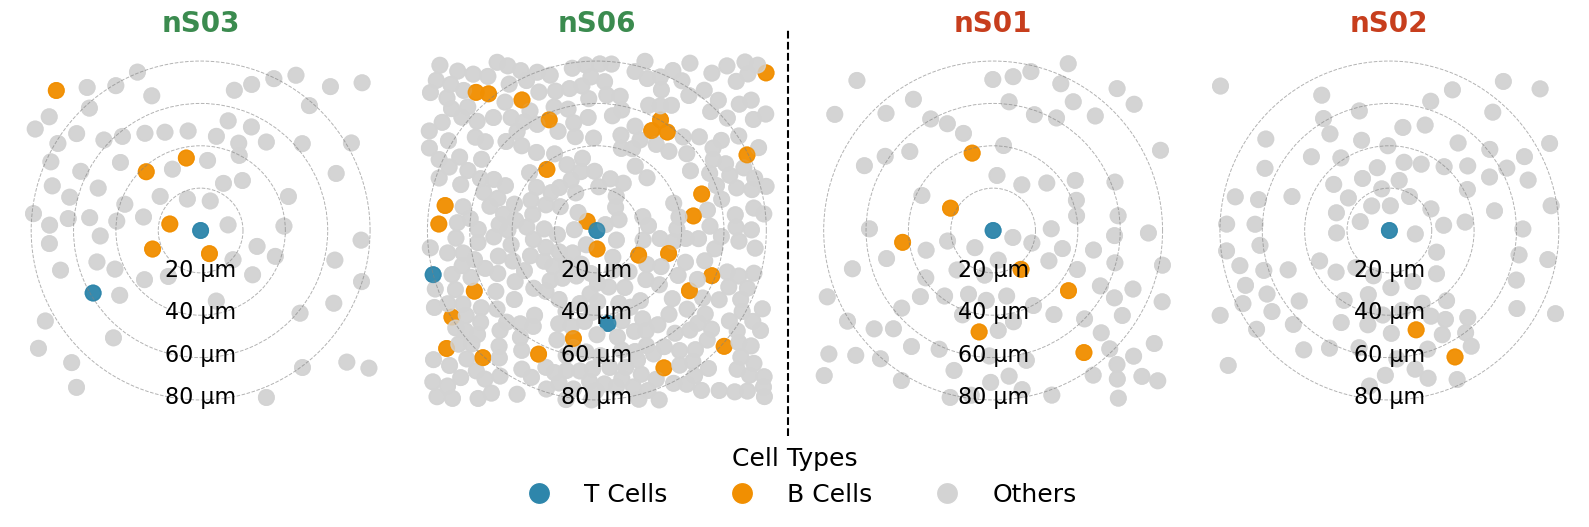

In [7]:
plot_HD(adata_HD)